In [161]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl

In [162]:
df = pd.read_excel('./outputs/trip_elevation_list/trips_with_route_elevation.xlsx', index_col=0)



In [163]:
df.columns

Index(['main_mode', 'route_distance_m', 'accumulated_ascent_m'], dtype='object')

In [ ]:
print(df["main_mode"].value_counts())  


main_mode
Car                       3152
Walk                      1807
Bus                        417
Rail                       128
Bicycle                    109
Motorcycle                  68
Tram                        50
Vehicle-like devices        30
Moped                        8
Taxi                         6
Coach                        5
Postbus                      3
Truck                        2
Other public transport       1
Name: count, dtype: int64


In [165]:
df[df['main_mode'] == 'Bicycle']['route_distance_m'].describe()

count      109.000000
mean      2533.188668
std       3516.348465
min        240.302323
25%        790.876547
50%       1241.198471
75%       2532.008781
max      28757.716729
Name: route_distance_m, dtype: float64

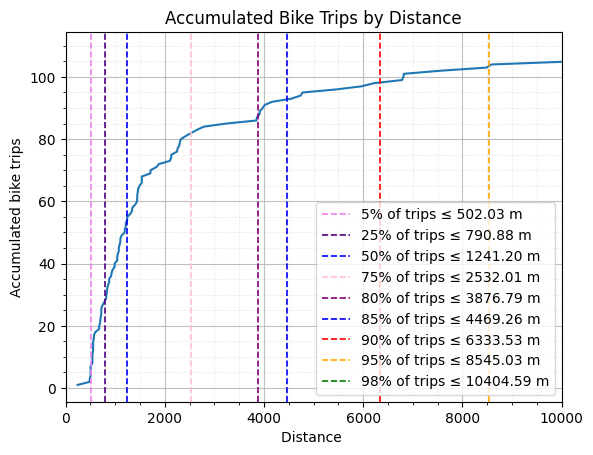

In [166]:
bike_trips = df[df['main_mode'] == 'Bicycle'].sort_values('route_distance_m')

# Accumulate bike trips by distance
bike_trips['cumulative_trips'] = np.arange(1, len(bike_trips) + 1)

# Plot accumulated bike trips vs distance
plt.plot(bike_trips['route_distance_m'], bike_trips['cumulative_trips'])
plt.xlabel('Distance ')
plt.ylabel('Accumulated bike trips')
plt.title('Accumulated Bike Trips by Distance')
# Set maximum x-axis value (adjust as needed)
max_x = 10*1000

plt.xlim(0, max_x)

# Fine-grained grid: major grid lines plus minor grid lines
plt.minorticks_on()
plt.grid(which='major', linestyle='-', linewidth=0.8, alpha=0.8)
plt.grid(which='minor', linestyle=':', linewidth=0.5, alpha=0.5)


# Vertical lines at 85%, 90%, 95% and 98% of accumulated bike trips
for pct, color in [(5, 'violet'), (25, 'indigo'), (50, 'blue'), (75, 'pink'),(80, 'purple'), (85, 'blue'), (90, 'red'), (95, 'orange'), (98, 'green')]:
    dist_pct = np.percentile(bike_trips['route_distance_m'], pct)
    plt.axvline(dist_pct, color=color, linestyle='--', linewidth=1.2,
                label=f'{pct}% of trips ≤ {dist_pct:.2f} m')

plt.legend()

# Based on this plot we can that most trips lie between 500 and 4000 meters. This accounts for about 75% of all trips. After this, we see quite a flattening. # We could also pick the upper threshold at arount 2500, before the big flattening. This would account for about 70% of all trips.

In [167]:
MIN_LENGTH = 500
MAX_LENGTH = 2500


In [168]:
df["slope"] = df["accumulated_ascent_m"] / df["route_distance_m"] * 100

Text(0, 0.5, 'Slope (per mille)')

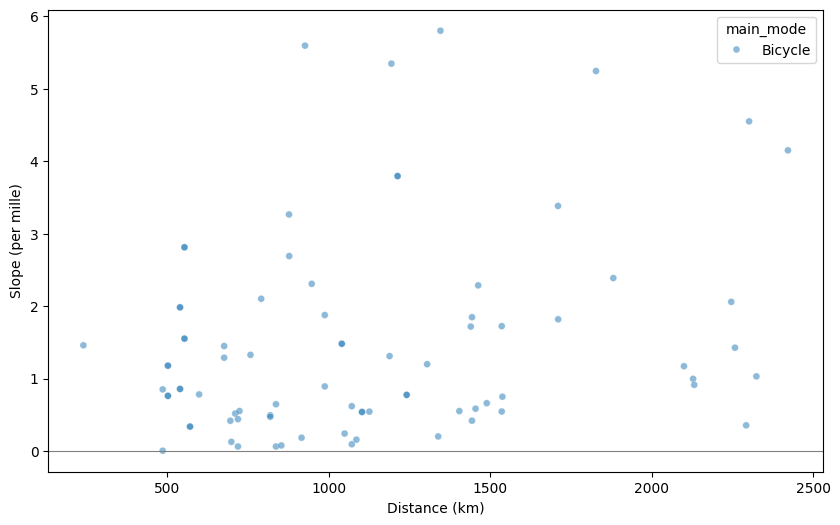

In [169]:
# Plot slope vs trip distance, colored by transport mode
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df[(df['main_mode'] == 'Bicycle') & (df["route_distance_m"] < MAX_LENGTH)].sort_values('route_distance_m'), x='route_distance_m', y='slope', hue='main_mode', alpha=0.5, s=25)
plt.axhline(0, color='gray', linewidth=0.8)
plt.xlabel('Distance (km)')
plt.ylabel('Slope (per mille)')

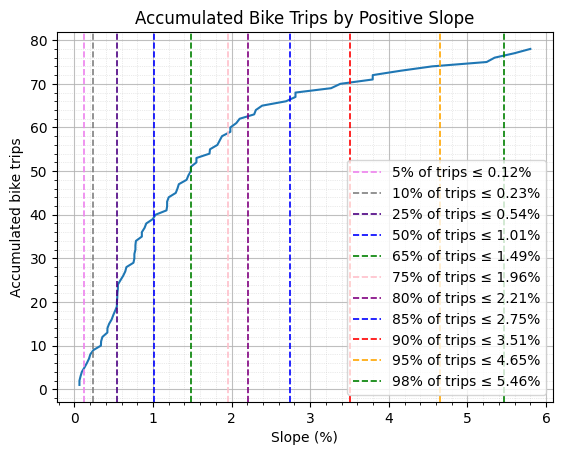

In [170]:
# Filter bike trips with positive slope and sort by slope
bike_trips_pos_slope = df[(df['main_mode'] == 'Bicycle') & (df['route_distance_m'] > MIN_LENGTH) & (df['route_distance_m'] < MAX_LENGTH)].sort_values('slope')

# Accumulate bike trips by slope
bike_trips_pos_slope['cumulative_trips'] = np.arange(1, len(bike_trips_pos_slope) + 1)

# Plot accumulated bike trips vs slope
plt.plot(bike_trips_pos_slope['slope'], bike_trips_pos_slope['cumulative_trips'])
plt.xlabel('Slope (%)')
plt.ylabel('Accumulated bike trips')
plt.title('Accumulated Bike Trips by Positive Slope')

# Fine-grained grid: major grid lines plus minor grid lines
plt.minorticks_on()
plt.grid(which='major', linestyle='-', linewidth=0.8, alpha=0.8)
plt.grid(which='minor', linestyle=':', linewidth=0.5, alpha=0.5)

# Vertical lines at percentiles of accumulated bike trips
for pct, color in [(5, 'violet'), (10, 'gray'), (25, 'indigo'), (50, 'blue'), (65, 'green'), (75, 'pink'), (80, 'purple'), (85, 'blue'), (90, 'red'), (95, 'orange'), (98, 'green')]:
    slope_val = np.percentile(bike_trips_pos_slope['slope'], pct)
    plt.axvline(slope_val, color=color, linestyle='--', linewidth=1.2,
                label=f'{pct}% of trips ≤ {slope_val:.2f}%')

plt.legend()
plt.show()

It starts flattening at about 90% which is at 3% slope.
This is empirical choice, but we choose the intervals [0.34, 0.62] (10-25%) and [1.55, 2.06] (65-80%). 
which is both are 10 from either end and 15pp wide.

In [171]:
MIN_INTERVAL = [0.23, 0.54]  # 10-25%
MAX_INTERVAL = [1.49, 2.21]  # 65-80%
MAX_INTERVAL = [1.01, 1.49]  # 65-80%

In [172]:
relevant_trips = df[(df['slope'] >= MIN_INTERVAL[0]) & (df['slope'] <= MAX_INTERVAL[1]) & (df['route_distance_m'] >= MIN_LENGTH) & (df['route_distance_m'] <= MAX_LENGTH)]
print(f"Number of relevant trips: {len(relevant_trips)}")
low_interval_trips = relevant_trips[(relevant_trips['slope'] >= MIN_INTERVAL[0]) & (relevant_trips['slope'] <= MIN_INTERVAL[1])]
high_interval_trips = relevant_trips[(relevant_trips['slope'] >= MAX_INTERVAL[0]) & (relevant_trips['slope'] <= MAX_INTERVAL[1])]
low_interval_mean_slope = low_interval_trips['slope'].mean()
high_interval_mean_slope = high_interval_trips['slope'].mean()

lower_slope_bike_share = len(low_interval_trips[low_interval_trips['main_mode'] == 'Bicycle']) / len(low_interval_trips)
high_slope_bike_share = len(high_interval_trips[high_interval_trips['main_mode'] == 'Bicycle']) / len(high_interval_trips)


print(f"""
For this we are considering only trips with distance between {MIN_LENGTH} m and {MAX_LENGTH} m, which includes 70% of biking trips.
This is divided into two groups: trips with slope between {MIN_INTERVAL[0]:.2f}% and {MIN_INTERVAL[1]:.2f}% (15% of biking trips) and trips with slope between {MIN_INTERVAL[1]:.2f}% and {MAX_INTERVAL[1]:.2f}% (15% of biking trips).
For each group, we calculate the share of trips that are biking trips.
Based on this result we can calculate the beta coefficient for slope in the utility function of biking trips, which is a measure of how much the slope affects the likelihood of choosing biking as a mode of transport.
""")
print(f"Bike share for lower slope trips: {lower_slope_bike_share:.2%}")
print(f"Bike share for higher slope trips: {high_slope_bike_share:.2%}")
beta_slope1 = (high_slope_bike_share - lower_slope_bike_share)/lower_slope_bike_share / (high_interval_mean_slope - low_interval_mean_slope)/low_interval_mean_slope
beta_slope = (high_slope_bike_share - lower_slope_bike_share)/ (high_interval_mean_slope - low_interval_mean_slope)
print(f"Beta coefficient for slope: {beta_slope:.5f}")
print(f"Beta coeffcient for slope using new model: {beta_slope1:.5f}")

Number of relevant trips: 981

For this we are considering only trips with distance between 500 m and 2500 m, which includes 70% of biking trips.
This is divided into two groups: trips with slope between 0.23% and 0.54% (15% of biking trips) and trips with slope between 0.54% and 1.49% (15% of biking trips).
For each group, we calculate the share of trips that are biking trips.
Based on this result we can calculate the beta coefficient for slope in the utility function of biking trips, which is a measure of how much the slope affects the likelihood of choosing biking as a mode of transport.

Bike share for lower slope trips: 3.47%
Bike share for higher slope trips: 4.35%
Beta coefficient for slope: 0.01018
Beta coeffcient for slope using new model: 0.76479


/var/folders/t_/q1zyhqk52hb1n2tywl2wjpqw0000gn/T/ipykernel_22167/1908858985.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  relevant_trips_for_plotting['slope_interval'] = pd.cut(relevant_trips_for_plotting['slope'], bins=slope_bins)


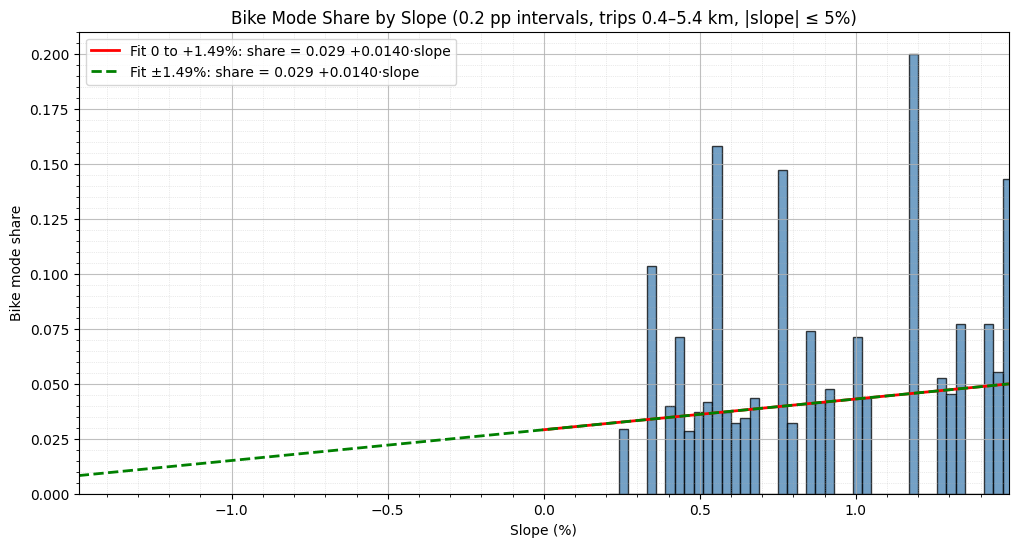

Positive-slope regression (0 to 1.49%): slope = 0.0140, intercept = 0.0291
Full-range regression (±1.49%): slope = 0.0140, intercept = 0.0291


,slope_interval,bike_share,n_trips,slope_mid
0,"(0.21, 0.24]",0.000000,9,0.225
1,"(0.24, 0.27]",0.029412,34,0.255
2,"(0.27, 0.3]",0.000000,27,0.285
3,"(0.3, 0.33]",0.000000,25,0.315
4,"(0.33, 0.36]",0.103448,29,0.345
5,"(0.36, 0.39]",0.000000,25,0.375
6,"(0.39, 0.42]",0.040000,25,0.405
7,"(0.42, 0.45]",0.071429,28,0.435
8,"(0.45, 0.48]",0.028571,35,0.465
9,"(0.48, 0.51]",0.037037,27,0.495


In [173]:
# Divide relevant trips into slope intervals of 0.2 percentage points
relevant_trips_for_plotting = relevant_trips
bin_width = .03
max_gradient = MAX_INTERVAL[1]  # limit plot to ±5% slope
slope_bins = np.arange(
    np.floor(relevant_trips_for_plotting['slope'].min() / bin_width) * bin_width,
    np.ceil(relevant_trips_for_plotting['slope'].max() / bin_width) * bin_width + bin_width,
    bin_width
)
relevant_trips_for_plotting['slope_interval'] = pd.cut(relevant_trips_for_plotting['slope'], bins=slope_bins)

# Bike mode share and trip count per slope interval
bike_share_by_slope = (
    relevant_trips_for_plotting
    .assign(is_bike=relevant_trips_for_plotting['main_mode'] == 'Bicycle')
    .groupby('slope_interval', observed=True)
    .agg(bike_share=('is_bike', 'mean'), n_trips=('is_bike', 'size'))
    .reset_index()
)
# .map on a categorical column keeps the categorical dtype -> convert to float
bike_share_by_slope['slope_mid'] = bike_share_by_slope['slope_interval'].map(lambda iv: iv.mid).astype(float)

# Restrict to intervals within ±5% gradient
bike_share_limited = bike_share_by_slope[bike_share_by_slope['slope_mid'].abs() <= max_gradient]

# Plot bike share per slope interval
plt.figure(figsize=(12, 6))
plt.bar(bike_share_limited['slope_mid'], bike_share_limited['bike_share'],
        width=bin_width, color='steelblue', edgecolor='black', alpha=0.75)
plt.axhline(0, color='gray', linewidth=0.8)
plt.xlim(-max_gradient, max_gradient)
plt.xlabel('Slope (%)')
plt.ylabel('Bike mode share')
plt.title('Bike Mode Share by Slope (0.2 pp intervals, trips 0.4–5.4 km, |slope| ≤ 5%)')
plt.minorticks_on()
plt.grid(which='major', linestyle='-', linewidth=0.8, alpha=0.8)
plt.grid(which='minor', linestyle=':', linewidth=0.5, alpha=0.5)

# Regression 1: positive slopes only (0 to max_gradient)
pos = bike_share_limited[bike_share_limited['slope_mid'] >= 0]
slope_pos, intercept_pos = np.polyfit(pos['slope_mid'], pos['bike_share'], 1)
x_pos = np.linspace(0, max_gradient, 100)
plt.plot(x_pos, intercept_pos + slope_pos * x_pos, color='red', linewidth=2,
         label=f'Fit 0 to +{max_gradient}%: share = {intercept_pos:.3f} {slope_pos:+.4f}·slope')

# Regression 2: full range (-max_gradient to max_gradient)
slope_all, intercept_all = np.polyfit(bike_share_limited['slope_mid'], bike_share_limited['bike_share'], 1)
x_all = np.linspace(-max_gradient, max_gradient, 100)
plt.plot(x_all, intercept_all + slope_all * x_all, color='green', linewidth=2, linestyle='--',
         label=f'Fit ±{max_gradient}%: share = {intercept_all:.3f} {slope_all:+.4f}·slope')

plt.legend()
plt.show()

print(f"Positive-slope regression (0 to {max_gradient}%): slope = {slope_pos:.4f}, intercept = {intercept_pos:.4f}")
print(f"Full-range regression (±{max_gradient}%): slope = {slope_all:.4f}, intercept = {intercept_all:.4f}")

bike_share_limited